# Recap

1. j'ai utilisé les llm pour faire l'extraction de données (feedable dans ai-rchivist)
2. j'ai fine tuné xlm-roberta sur le corpus de l'univ de Tours pour être capable de faire de la NER
3. j'ai demandé aux gens de labelliser le corpus
4. j'ai fine tuné plusieurs modèles pour faire de la NER
    * xaviergillard/xlm-roberta-vieille-france-v2   (fine tuning)
    * xaviergillard/xlm-roberta-vieille-france-v2.1 (idem, plus d'epochs)
    * xaviergillard/brabrant-xvii-ner (xlmr entrainé directement sur les données)
    * xaviergillard/brabrant-scratch-ner (bert custom entrainé sur les données) 

In [1]:
import json
import typing
import pandas as pd
import numpy  as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from pathlib         import Path
from pydantic        import BaseModel
from transformers    import AutoTokenizer, AutoModelForTokenClassification
from datasets        import Dataset
from seqeval.metrics import precision_score, recall_score, f1_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

/home/xgillard/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Step 1: on prépare le gold standard pour évaluer

In [2]:
class Annotation(BaseModel):
    start:  int
    end:    int
    labels: list[str]
    text:   str

    @property
    def label(self):
        return self.labels[0]
        
    def __lt__(self, other) -> bool:
        return ( (self.start < other.start)
            or   ((self.start == other.start) and (self.end < other.end)) )

In [3]:
def simplify_labelstudio_output(item):
    return {
        "id"      : item["data"]["id"],
        "text"    : item["data"]["text"],
        "annotations": sorted([ Annotation.model_validate(r["value"]) for a in item["annotations"] for r in a["result"]])
    }

def align_words_with_labels(text: str, annotations: list[Annotation]) -> tuple[list[str], list[str]]:
    classes= {'PERSON': 'PERS', 'LOCATION': 'LOC', 'DATE': 'DATE', 'O': 'O'}
    tokens = text.split()
    labels = [ 'O' for _ in tokens ]

    annots = iter(annotations)
    # on assigne grossierement les labels
    token = 0
    try:
        annot = next(annots)
        for i,c in enumerate(text):
            if i > 0 and c.isspace() and not text[i-1].isspace():
                token += 1
            if i >= annot.start and i < annot.end:
                labels[token] = classes[annot.label]
            if i >= annot.end:
                annot = next(annots)
    except StopIteration:
        pass
    # on s'assure de respecter le protocole IOB
    for i,l in enumerate(labels):
        if l == 'O':
            continue
        if i == 0:
            labels[i] = f'B-{l}'
        prev = labels[i-1]
        if prev == f'B-{l}' or prev == f'I-{l}':
            labels[i] = f'I-{l}'
        else:
            labels[i] = f'I-{l}'
    # ok on a fini
    return tokens, labels

def process_item(item):
    item = simplify_labelstudio_output(item)
    x,y  = align_words_with_labels(item['text'], item['annotations'])
    return {'id': item["id"], 'tokens': x, 'labels': y}

gold = [process_item(item) for item in json.loads(Path("GOLD_STD_LABELS.json").read_text(encoding="utf8")) ]
gold = pd.DataFrame(gold, columns=["id", "tokens", "labels"]).set_index(["id"])
gold.to_parquet('gold_dataset.parquet')
gold[:5]

,tokens,labels
id,,
279,"[pardon, moyennisse, amende, kaerle, etc., all...","[O, O, O, I-PERS, O, O, O, O, O, O, O, O, O, O..."
313,"[kaerle, etc., doen, te, weeten, allen, tegenw...","[I-PERS, O, O, O, O, O, O, O, O, O, O, O, O, O..."
416,"[kaerle, etc., doen, te, wetene, allen, iegewo...","[I-PERS, O, O, O, O, O, O, O, O, O, O, O, O, O..."
390,"[philips, etc, doen, te, wetene, dat, wij, heb...","[I-PERS, O, O, O, O, O, O, O, O, O, O, O, I-PE..."
72,"[remissie, charles, etc, savoir, faisons, a, t...","[O, I-PERS, O, O, O, O, O, O, O, O, O, O, O, O..."


## Step 2: 

In [4]:
device     = "cuda" if torch.cuda.is_available() else "cpu"

#checkpoint = "xaviergillard/xlm-roberta-large-vieille-france"
checkpoint = "xaviergillard/xlm-roberta-vieille-france-v2"
tokenizer  = AutoTokenizer.from_pretrained("xaviergillard/xlm-roberta-large-vieille-france")
model      = AutoModelForTokenClassification.from_pretrained("xaviergillard/xlm-roberta-vieille-france-v2").eval().to(device)

In [5]:
def make_dataset(tokenizer, gold):
    """
    Crée le dataset correspondant au corpus complet tokenizé avec les labels qui sont correctement
    alignés sur les tokens. Ca renvoie un dataset avec les colonnes suivantes: 
    - input_ids
    - attention_mask
    - labels
    - tokens
    - tags
    """
    # on commence par tout tokenizer en batch
    max_seq_len= tokenizer.model_max_length
    tokenized  = tokenizer(
        gold['tokens'].tolist(), 
        is_split_into_words=True,
        padding=True, 
        truncation=True,
        max_length=max_seq_len,
        return_overflowing_tokens=True,
    )
    # on aligne les labels avec les tokens dans les différentes séquences qui découpent le texte
    tokids = []
    labels = []
    amasks = []
    tokens = []
    classes= []
    for i, token_ids in enumerate(tokenized['input_ids']):
        sample_id  = tokenized['overflow_to_sample_mapping'][i]
        encoding   = tokenized.encodings[i]
        word_ids   = encoding.word_ids
        decoded    = [ tokenizer.convert_ids_to_tokens(tid) for tid in token_ids ]
        labelclass = [ gold.iloc[sample_id]['labels'][w] if w is not None else 'IGN' for w in word_ids ]
        # on fait une passe pour corriger les B- labels qui appartiennent au meme mot.
        for k,wid in enumerate(word_ids):
            if k == 0:
                continue
            if wid == word_ids[k-1] and labelclass[k].startswith('B-'):
                labelclass[k] = 'I-' + labelclass[k][2:]
        # on construit la liste d'id pour les labels
        labelids   = [ model.config.label2id[l] for l in labelclass ]
        amasks .append(tokenized['attention_mask'][i])
        tokens .append(decoded)
        tokids .append(token_ids)
        classes.append(labelclass)
        labels .append(labelids)
    # on convertit le tout en un dataset
    return Dataset.from_pandas(pd.DataFrame({'input_ids': tokids, 'attention_mask': amasks, 'tokens': tokens,'tags': classes, 'labels': labels}))


In [6]:
#ds = make_dataset(tokenizer, gold)
#ds.to_parquet('gold.xlmroberta.parquet')
#ds

In [7]:
ds = Dataset.from_parquet('gold.xlmroberta.parquet')
ds

Dataset({
    features: ['input_ids', 'attention_mask', 'tokens', 'tags', 'labels'],
    num_rows: 2086
})

In [8]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def align_and_filter(preds, grounds, errors):
    '''
    Renvoie un tuple comprenant 2 list[list[str]] qui sont les prédictions et la ground truth
    de sorte qu'ils soient filtrés pour ignorer les labels qui sont 'IGN'
    '''
    predictions = []
    ground_truth= []
    token_error = []
    
    for ps, gs,es in zip(preds,grounds, errors):
        pred   = []
        ground = []
        error  = []
    
        for p,g,e in zip(ps, gs, es):
            if g != 'IGN':
                pred.append(p)
                ground.append(g)
                error.append(e)
        predictions.append(pred)
        ground_truth.append(ground)
        token_error.append(error)
    #
    return predictions, ground_truth, token_error

@torch.no_grad()
def process_one_batch(model, batch, device=DEVICE):
    '''
    Renvoie un tuple comprenant 2 list[list[str]] qui sont les prédictions et la ground truth
    et une list[list[float]] qui comprend l'erreur par token.
    '''
    model     = model.eval()
    id2label  = model.config.id2label
    input_ids = torch.tensor(batch['input_ids'], dtype=torch.int, device=device)
    attn_mask = torch.tensor(batch['attention_mask'], dtype=torch.int, device=device)
    logits    = model(input_ids=input_ids, attention_mask=attn_mask).logits
    labels    = torch.tensor(batch['labels']).to(device)
    pertoken  = (-1, len(id2label))
    error     = F.cross_entropy(logits.view(pertoken), labels.view(-1), reduction='none') 
    predicted = logits.argmax(-1).detach().cpu().numpy().tolist()
    predicted = [[id2label[p] for p in preds] for preds in predicted]
    error     = error.view(logits.shape[:2]).tolist()
    gt        = batch['tags']
    return predicted, gt, error

In [ ]:
def explode_it_all(ds):
    df = ds.to_pandas()
    
    df2 = (df[['tokens', 'tags']]).explode(['tokens', 'tags'])
    df2 = df2[df2['tags'] != 'IGN']
    df3 = (df[['labels', 'predictions', 'error']]).explode(['labels', 'predictions', 'error'])
    
    return pd.concat([df2, df3], axis=1)

def most_wrong(df):
    return (df.groupby('tokens')[['error']]
         .agg(['count', 'mean', 'sum'])
         .droplevel(0, axis=1)
         .sort_values(by='mean', ascending=False)
    ).head(10)

def plot_confusion_matrix(predictions, ground_truth, labels):
    C = len(labels)
    confusion = confusion_matrix(predictions, ground_truth, normalize='true')
    fig, ax = plt.subplots(figsize=(C, C))
    display = ConfusionMatrixDisplay(confusion_matrix=confusion, display_labels=labels)
    display.plot(cmap="Blues", values_format=".2f", ax=ax, colorbar=False)
    plt.show()

def error_analysis(model, ds):
    cat = [v for v in model.config.id2label.values() if v != 'IGN']
    df  = explode_it_all(ds)

    print("========== HIGHEST ERRORS ======================")
    print(most_wrong(df))
    print("========== CONFUSION MATRIX ====================")
    plot_confusion_matrix(df['predictions'], df['labels'], cat)

def assess_performance(name, model, tokenizer, gold):
    def dataset_batch_processor(batch):
        p, g, e = process_one_batch(model, batch)
        p, g, e = align_and_filter(p, g, e)
        return {'predictions': p, 'labels': g, 'error': e}
    
    ds = make_dataset(tokenizer, gold)
    ds = ds.map(dataset_batch_processor, batched=True, batch_size=100)

    print(f"********* {name} ******************************")
    print("########## PERFORMANCE REPORT ###################")
    print(classification_report(ds['predictions'], ds['labels']))
    print("########## ERROR ANALYSIS #######################")
    error_analysis(model, ds)
    return ds

Map: 100%|███████████████████████████████████████████████████████████████████| 2086/2086 [02:42<00:00, 12.80 examples/s]


********* xaviergillard/xlm-roberta-large-vieille-france ******************************
########## PERFORMANCE REPORT ###################
              precision    recall  f1-score   support

        DATE       0.03      0.09      0.05       344
         LOC       0.01      0.01      0.01      8603
        PERS       0.15      0.10      0.12     11893

   micro avg       0.08      0.06      0.07     20840
   macro avg       0.06      0.06      0.06     20840
weighted avg       0.09      0.06      0.07     20840

########## ERROR ANALYSIS #######################
========== HIGHEST ERRORS ======================
          count       mean        sum
tokens                               
▁two          1  17.159973  17.159973
▁mense        1  17.079475  17.079475
kom           4  16.845547  67.382187
▁juridic      1   16.80706   16.80706
touch         1  16.723612  16.723612
usele         1  16.616402  16.616402
huis          1  16.314356  16.314356
nout          1  16.289003  16.289003
ir

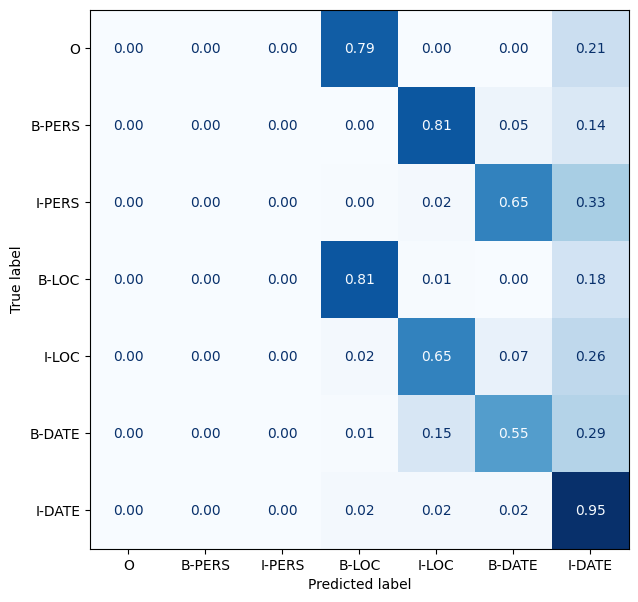

In [74]:
checkpoint = "xaviergillard/xlm-roberta-large-vieille-france"
tokenizer  = AutoTokenizer.from_pretrained("xaviergillard/xlm-roberta-large-vieille-france")
model      = AutoModelForTokenClassification.from_pretrained(checkpoint).eval().to(device)
ds2        = assess_performance(checkpoint, model, tokenizer, gold)

Map: 100%|███████████████████████████████████████████████████████████████████| 2086/2086 [02:37<00:00, 13.28 examples/s]


********* xaviergillard/xlm-roberta-vieille-france-v2 ******************************
########## PERFORMANCE REPORT ###################
              precision    recall  f1-score   support

        DATE       0.78      0.72      0.75      1042
         LOC       0.88      0.76      0.82      8676
        PERS       0.91      0.84      0.88      8257

   micro avg       0.89      0.80      0.84     17975
   macro avg       0.85      0.78      0.81     17975
weighted avg       0.89      0.80      0.84     17975

########## ERROR ANALYSIS #######################
========== HIGHEST ERRORS ======================
        count       mean        sum
tokens                             
▁sover      1  17.391001  17.391001
▁donar      1  16.367102  16.367102
▁hulle      1  16.150017  16.150017
ysa         1  16.054682  16.054682
▁luce       5  15.648078  78.240392
▁stir       1   15.42402   15.42402
▁svou       1  15.417405  15.417405
▁lod        1  15.405506  15.405506
▁roh        2  15.349568 

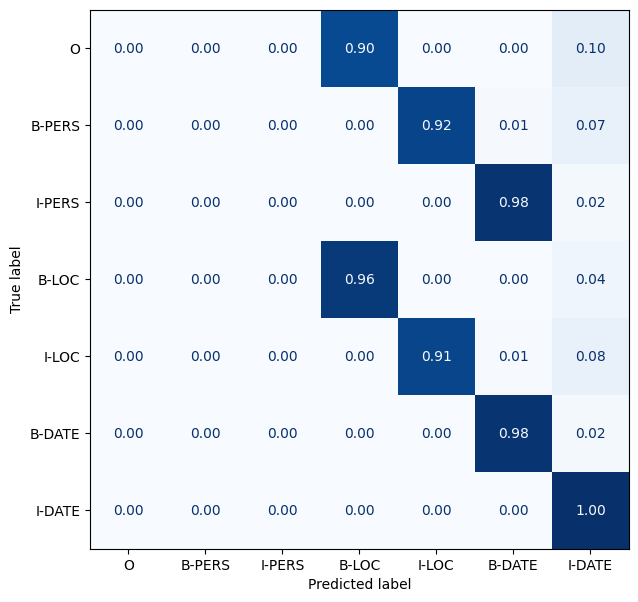

In [ ]:
checkpoint = "xaviergillard/xlm-roberta-vieille-france-v2"
tokenizer  = AutoTokenizer.from_pretrained("xaviergillard/xlm-roberta-large-vieille-france")
model      = AutoModelForTokenClassification.from_pretrained(checkpoint).eval().to(device)
ds2        = assess_performance(checkpoint, model, tokenizer, gold)

Map: 100%|███████████████████████████████████████████████████████████████████| 2086/2086 [02:40<00:00, 13.01 examples/s]


********* xaviergillard/xlm-roberta-vieille-france-v2.1 ******************************
########## PERFORMANCE REPORT ###################
              precision    recall  f1-score   support

        DATE       0.72      0.61      0.66      1137
         LOC       0.86      0.74      0.80      8722
        PERS       0.90      0.80      0.85      8529

   micro avg       0.87      0.76      0.81     18388
   macro avg       0.82      0.72      0.77     18388
weighted avg       0.87      0.76      0.81     18388

########## ERROR ANALYSIS #######################
========== HIGHEST ERRORS ======================
           count       mean        sum
tokens                                
▁mercredi      1  12.575513  12.575513
▁spor          1  11.056609  11.056609
▁arra          2  10.870513  21.741027
▁hulle         1  10.688683  10.688683
▁jeudi         1  10.528666  10.528666
▁lova          2   10.25988  20.519759
▁hill          1  10.105214  10.105214
limo           2   9.922331  19.

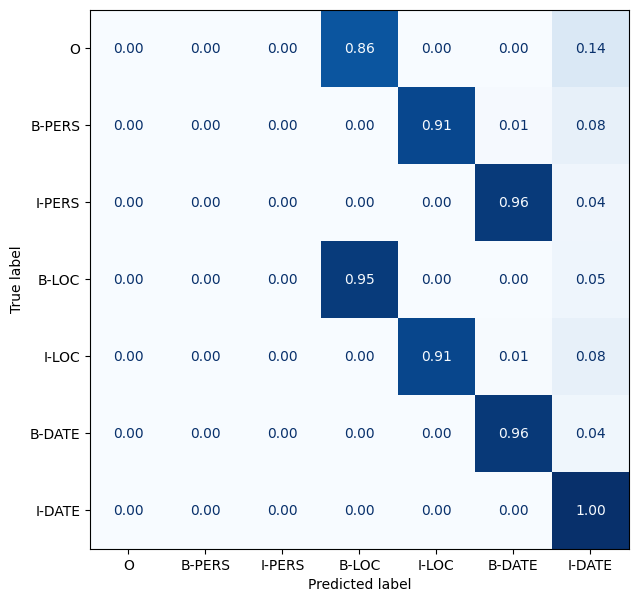

In [66]:
checkpoint = "xaviergillard/xlm-roberta-vieille-france-v2.1"
tokenizer  = AutoTokenizer.from_pretrained("xaviergillard/xlm-roberta-large-vieille-france")
model      = AutoModelForTokenClassification.from_pretrained(checkpoint).eval().to(device)
ds2        = assess_performance(checkpoint, model, tokenizer, gold)

Map: 100%|███████████████████████████████████████████████████████████████████| 2086/2086 [02:46<00:00, 12.53 examples/s]


********* xaviergillard/brabrant-xvii-ner ******************************
########## PERFORMANCE REPORT ###################
              precision    recall  f1-score   support

        DATE       0.77      0.69      0.73      1074
         LOC       0.87      0.77      0.82      8557
        PERS       0.91      0.83      0.87      8341

   micro avg       0.88      0.79      0.84     17972
   macro avg       0.85      0.77      0.81     17972
weighted avg       0.88      0.79      0.84     17972

########## ERROR ANALYSIS #######################
========== HIGHEST ERRORS ======================
        count       mean        sum
tokens                             
▁hulle      1  15.313266  15.313266
rinda       1  11.598559  11.598559
▁pale       4  11.044497  44.177986
▁jun        1  11.008074  11.008074
▁kit        1   10.85391   10.85391
▁mechi      1  10.776577  10.776577
▁sut        3  10.763272  32.289817
▁maand      1  10.707039  10.707039
▁west       1  10.686844  10.686844
▁

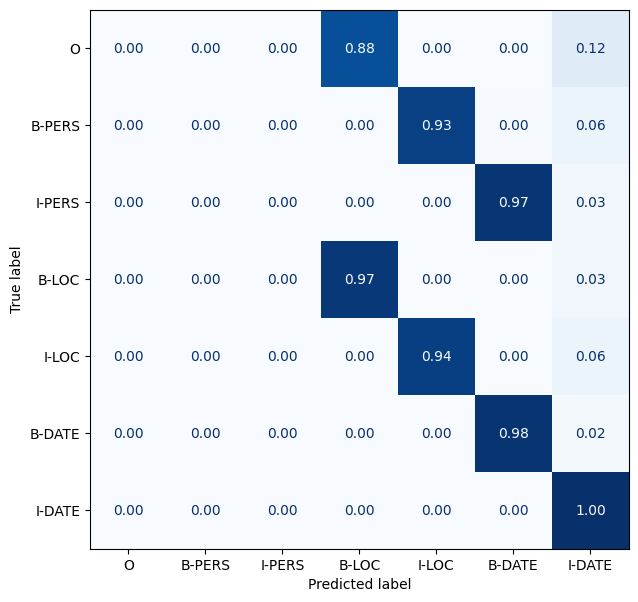

In [67]:
checkpoint = "xaviergillard/brabrant-xvii-ner"
tokenizer  = AutoTokenizer.from_pretrained("xaviergillard/xlm-roberta-large-vieille-france")
model      = AutoModelForTokenClassification.from_pretrained(checkpoint).eval().to(device)
ds2        = assess_performance(checkpoint, model, tokenizer, gold)

In [75]:
checkpoint = "xaviergillard/brabrant-scratch-ner"

tokenizer  = AutoTokenizer.from_pretrained("xaviergillard/brabant-xvii-from-scratch")
tokenizer.model_max_length = 512

model      = AutoModelForTokenClassification.from_pretrained(checkpoint).eval().to(device)
model.config.label2id['IGN'] = -100
model.config.id2label[-100] = 'IGN'

In [81]:
labels.view(pertoken).shape

torch.Size([320, 8])

In [77]:
batch     = ds2[:5]

model     = model.eval()
id2label  = model.config.id2label
input_ids = torch.tensor(batch['input_ids'], dtype=torch.int, device=device)
attn_mask = torch.tensor(batch['attention_mask'], dtype=torch.int, device=device)
logits    = model(input_ids=input_ids, attention_mask=attn_mask).logits
labels    = torch.tensor(batch['labels']).to(device)
pertoken  = (-1, len(id2label))
error     = F.cross_entropy(logits.view(pertoken), labels.view(-1), reduction='none') 
predicted = logits.argmax(-1).detach().cpu().numpy().tolist()
predicted = [[id2label[p] for p in preds] for preds in predicted]
error     = error.view(logits.shape[:2]).tolist()
gt        = batch['tags']
return predicted, gt, error

ValueError: Expected input batch_size (2240) to match target batch_size (2560).